# Reinforcement Learning Laboratory — Q-learning, DQN and Two Robots

**Artificial Intelligence (CS F407) — Laboratory Exercise: RL and Deep RL**
Using an LLM as an engineering assistant.

This notebook works through every task in `RL_lab.pdf` for the two-room warehouse:

* **Part I** — Task 1 (formulate the MDP), Task 2 (plan the agent), Task 3 (implement tabular
  Q-learning), Task 4 (test the environment and the TD update), Task 5 (train, evaluate,
  compare against a random policy, investigate exploration).
* **Part II** — Task 6: replace the Q-table with a Deep Q-Network (replay buffer + target network)
  and validate the loss before training.
* **Part III** — Task 7: one controller for two robots, simultaneous movement, collision rules,
  tests, training and greedy evaluation.
* **Task 8** — comparison of the three controllers, additional starts, reflection and the
  optional RLHF connection.

No path planner or ready-made RL library is used by any learner. Search appears only once, as an
independent *check* of the hand-computed shortest routes, and is never given to an agent.

## The Warehouse

A $5\times5$ grid, positions $(r,c)$ with rows increasing downwards. Two rooms joined by a single
doorway at $(2,2)$.

```
     c=0 1 2 3 4
r=0    . . # . .
r=1    . . # . .
r=2    S . D . G      D = doorway (2,2), the only gap in column 2
r=3    . . # . .
r=4    . . # . .
```

* Obstacles: $\{(0,2),(1,2),(3,2),(4,2)\}$. Start $S=(2,0)$, goal $G=(2,4)$.
* Actions (codes 0–4): **Up, Down, Left, Right, Wait**. A move into an obstacle or off the grid
  leaves the robot in place.
* Rewards (mutually exclusive): **+10** on reaching the goal, **−1** for an invalid move,
  **−0.1** for any other valid action (including Wait). $\gamma=0.95$.
* Reaching the goal **terminates**; an unfinished rollout is **truncated** after 40 steps.

In [1]:
import copy
import platform
from dataclasses import dataclass

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn

SEED = 7
torch.set_num_threads(1)  # tiny networks: one thread is faster and keeps runs reproducible

N = 5
OBSTACLES = frozenset({(0, 2), (1, 2), (3, 2), (4, 2)})
START, GOAL = (2, 0), (2, 4)
ACTIONS = ["Up", "Down", "Left", "Right", "Wait"]       # codes 0..4, in that order
DELTAS = [(-1, 0), (1, 0), (0, -1), (0, 1), (0, 0)]
GAMMA = 0.95
MAX_STEPS = 40

Pos = tuple[int, int]


def is_free(p: Pos) -> bool:
    r, c = p
    return 0 <= r < N and 0 <= c < N and p not in OBSTACLES


def idx(p: Pos) -> int:
    # Cell (r, c) -> row of the 25x5 Q-table / position of the 1 in the one-hot vector.
    return N * p[0] + p[1]


def render(paths: dict[str, list[Pos]] | None = None) -> str:
    # ASCII map; each path is drawn with its own symbol (later paths overwrite earlier ones).
    g = [["#" if (r, c) in OBSTACLES else "." for c in range(N)] for r in range(N)]
    for sym, path in (paths or {}).items():
        for p in path:
            g[p[0]][p[1]] = sym
    return "\n".join(" ".join(row) for row in g)


print(f"Python {platform.python_version()} | NumPy {np.__version__} | "
      f"Matplotlib {matplotlib.__version__} | PyTorch {torch.__version__} | seed {SEED}")
print()
print(render({"S": [START], "G": [GOAL]}))

Python 3.12.5 | NumPy 2.4.6 | Matplotlib 3.10.9 | PyTorch 2.10.0+cu128 | seed 7

. . # . .
. . # . .
S . . . G
. . # . .
. . # . .


# Part I — Design and Test a Q-learning Agent

## Task 1 — Understand the MDP

| Component | Specification |
|---|---|
| **State** | The robot's cell $(r,c)$, one of the 21 free cells (25 indices, obstacle rows unused). |
| **Actions** | $\{0{:}\text{Up},1{:}\text{Down},2{:}\text{Left},3{:}\text{Right},4{:}\text{Wait}\}$, all available in every state. |
| **Transition rule** | $s'=s+\Delta(a)$ if that cell is inside the grid and not an obstacle, otherwise $s'=s$. Wait gives $s'=s$. |
| **Reward** | $+10$ if $s'=G$; else $-1$ if the move was invalid; else $-0.1$. |
| **Initial state** | $S=(2,0)$. |
| **Terminal outcome** | Reaching $G=(2,4)$ (true termination). The 40-step cutoff is *truncation*, not a property of the task. |

**(a) What information is necessary to specify the state?** Everything that affects future
transitions and rewards: the map, the goal and the robot's position (and, strictly, whether the task
has ended).

**(b) Why is the current position sufficient?** The map and goal are fixed for the whole
experiment, so they are constants, not variables. Given the position, the next position and reward
depend only on the action — the history adds nothing (the Markov property). The step counter
matters only to the *collection* cutoff, which is not part of the task.

**(c) Is the transition rule deterministic?** Yes. Each (state, action) pair produces exactly one
next state and reward.

**(d) Shortest valid route from S to G?** Column 2 is blocked except at the doorway $(2,2)$, and S
and G are on row 2, so the route is four Rights:
$(2,0)\to(2,1)\to(2,2)\to(2,3)\to(2,4)$ — **4 steps**, return $3(-0.1)+10=9.7$.

**(e) Is finding that route by search the same as learning action values?** No. Search uses the
*known model* (the map) to plan a path offline. Q-learning is never given the map or a path: it
acts, observes rewards, and gradually estimates $Q(s,a)$ — the expected discounted return of taking
$a$ in $s$ and acting well afterwards. The greedy policy happens to coincide with the shortest path,
but it is learned from experience, and it covers every visited state, not just one route.

In [2]:
# Independent check of (d) only — this BFS is never used by any learner.
from collections import deque


def bfs_length(start: Pos, goal: Pos) -> int:
    frontier, seen = deque([(start, 0)]), {start}
    while frontier:
        p, d = frontier.popleft()
        if p == goal:
            return d
        for dr, dc in DELTAS[:4]:
            q = (p[0] + dr, p[1] + dc)
            if is_free(q) and q not in seen:
                seen.add(q)
                frontier.append((q, d + 1))
    return -1


print("Shortest route length from S to G (reference):", bfs_length(START, GOAL))
print("Shortest route length from (0,0) to G (used in Task 8):", bfs_length((0, 0), GOAL))

Shortest route length from S to G (reference): 4
Shortest route length from (0,0) to G (used in Task 8): 6


## Task 2 — Plan the Learning Agent

1. **Representation.** The map is a set of obstacle cells plus bounds; the robot position is a
   tuple `(r, c)`.
2. **`reset` / `step`.** `reset(start)` sets the position and the step counter $t=0$ and returns the
   state. `step(a)` computes the candidate cell, applies the stay-in-place rule, assigns the reward,
   increments $t$, and returns `next_state, reward, terminated, truncated, invalid`.
   `terminated` is true only on reaching G; `truncated` is true when $t=40$ and the task has not
   terminated.
3. **Q-table.** NumPy array of shape $25\times5$, initialised to zero; row $5r+c$, column = action
   code. Obstacle rows are never visited.
4. **Epsilon-greedy.** With probability $\varepsilon$ pick one of the 5 actions uniformly; otherwise
   pick uniformly among the actions tied at the maximum Q-value (random tie-breaking in training).
5. **Terminal flag in the target.** $y=r$ if `terminated`, else $y=r+\gamma\max_{a'}Q(s',a')$.
   Truncation **does** bootstrap, using the next state returned by `step` *before* any reset.
6. **Episode end.** On termination or truncation, whichever comes first.
7. **Training vs evaluation.** Training: $\varepsilon$ decays linearly $1\to0.05$ over 1,200 of
   1,500 episodes, and every step updates the table. Evaluation: $\varepsilon=0$, **no updates**,
   fixed tie-break (`np.argmax`, lowest action code), from a chosen start.

**Recorded:** episode return and success, $\varepsilon$ per episode, invalid moves, timeouts, and the
final greedy trajectory with its length.

## Task 3 — Implementation (the "LLM-generated" Q-learning agent)

The prompt, adapted from the PDF and carrying our full design:

> Implement tabular Q-learning in Python using NumPy for this warehouse: a 5×5 grid, obstacles
> {(0,2),(1,2),(3,2),(4,2)}, start (2,0), goal (2,4). Actions up, down, left, right, wait (codes
> 0–4). An obstacle or boundary move stays in place. Mutually exclusive rewards: +10 on reaching the
> goal, −1 for an invalid move, −0.1 for another valid action. Separate functions for the
> environment, epsilon-greedy selection, one Q-learning update, training and greedy evaluation.
> α=0.2, γ=0.95, zero-initialised Q-table, seed 7, 1,500 episodes, ε linear from 1 to 0.05 over the
> first 1,200 episodes. Cut off unfinished episodes after 40 steps and return separate termination
> and truncation flags. Bootstrap at truncation but not at goal termination; use the next state from
> before reset in every update. No path search, no RL library. Include a test mode where I set the
> position, choose one action and inspect the outcome without training.

The code below implements exactly that specification. `set_position` + `step` is the test mode.

In [3]:
@dataclass(frozen=True)
class Step:
    next_state: object      # Pos for one robot, (Pos, Pos) for two
    reward: float
    terminated: bool        # true end of the task (goal, or collision / both arrived for two robots)
    truncated: bool         # 40-step collection cutoff — NOT a task outcome
    invalid: int            # number of invalid (obstacle/boundary) moves in this step
    collision: bool = False
    success: bool = False


class WarehouseEnv:
    # Single-robot environment. Deterministic; knows nothing about learning.

    def __init__(self, start: Pos = START, goal: Pos = GOAL, max_steps: int = MAX_STEPS):
        self.start, self.goal, self.max_steps = start, goal, max_steps
        self.reset()

    def reset(self, start: Pos | None = None) -> Pos:
        self.pos = start if start is not None else self.start
        if not is_free(self.pos):
            raise ValueError(f"start {self.pos} is not a free cell")
        self.t = 0
        return self.pos

    def set_position(self, pos: Pos) -> Pos:
        # Test mode: place the robot anywhere free, without training.
        return self.reset(pos)

    def step(self, a: int) -> Step:
        dr, dc = DELTAS[a]
        cand = (self.pos[0] + dr, self.pos[1] + dc)
        invalid = not is_free(cand)                  # Wait is never invalid: cand == pos
        self.pos = self.pos if invalid else cand
        self.t += 1
        if self.pos == self.goal:
            reward, terminated = 10.0, True
        elif invalid:
            reward, terminated = -1.0, False
        else:
            reward, terminated = -0.1, False
        truncated = (not terminated) and self.t >= self.max_steps
        return Step(self.pos, reward, terminated, truncated, int(invalid), success=terminated)


def epsilon_greedy(q_row: np.ndarray, eps: float, rng: np.random.Generator) -> int:
    # Explore with prob. eps; otherwise greedy with RANDOM tie-breaking (training only).
    if rng.random() < eps:
        return int(rng.integers(len(q_row)))
    best = np.flatnonzero(q_row == q_row.max())
    return int(rng.choice(best))


def td_target(r: float, max_next_q: float, terminated: bool, gamma: float = GAMMA) -> float:
    # Only TRUE termination removes the continuation term; truncation bootstraps.
    return r if terminated else r + gamma * max_next_q


def q_update(Q: np.ndarray, s: int, a: int, r: float, s_next: int, terminated: bool,
             alpha: float, gamma: float = GAMMA) -> float:
    # One tabular Q-learning update; touches only Q[s, a]. Returns the target y.
    y = td_target(r, float(Q[s_next].max()), terminated, gamma)
    Q[s, a] += alpha * (y - Q[s, a])
    return y


def linear_eps(i: int, decay_len: int, start: float = 1.0, end: float = 0.05) -> float:
    return start + (end - start) * min(i / decay_len, 1.0)


def train_q(episodes: int = 1500, alpha: float = 0.2, decay_episodes: int = 1200,
            eps_schedule=None, seed: int = SEED) -> tuple[np.ndarray, dict]:
    rng = np.random.default_rng(seed)
    Q = np.zeros((N * N, len(ACTIONS)))
    env = WarehouseEnv()
    log = {k: [] for k in ("ret", "success", "eps", "invalid", "timeout", "length")}
    for ep in range(episodes):
        eps = eps_schedule(ep) if eps_schedule else linear_eps(ep, decay_episodes)
        s, G, inv = env.reset(), 0.0, 0
        while True:
            a = epsilon_greedy(Q[idx(s)], eps, rng)
            st = env.step(a)
            # st.next_state is the state BEFORE any reset — correct for truncated updates too.
            q_update(Q, idx(s), a, st.reward, idx(st.next_state), st.terminated, alpha)
            G += st.reward
            inv += st.invalid
            s = st.next_state
            if st.terminated or st.truncated:
                break
        for k, v in zip(log, (G, st.success, eps, inv, st.truncated, env.t)):
            log[k].append(v)
    return Q, log


def greedy_rollout(env, start, choose) -> dict:
    # Evaluation: no exploration, no updates. `choose(state) -> action` must be deterministic.
    s = env.reset(start)
    states, actions, invalid, total = [s], [], 0, 0.0
    while True:
        a = choose(s)
        st = env.step(a)
        actions.append(a)
        invalid += st.invalid
        total += st.reward
        s = st.next_state
        states.append(s)
        if st.terminated or st.truncated:
            break
    return {"states": states, "actions": actions, "steps": len(actions), "invalid": invalid,
            "success": st.success, "collision": st.collision, "timeout": st.truncated,
            "return": total}


def q_policy(Q: np.ndarray):
    return lambda s: int(np.argmax(Q[idx(s)]))   # fixed tie-break: lowest action code

## Task 4 — Test the Environment and the Q-learning Update

### Environment tests (no learner, position set explicitly)

In [4]:
env = WarehouseEnv()
U, D, L, R, W = range(5)
env_tests = [
    # (position, action, expected next, expected reward, expected terminated)
    ((0, 0), U, (0, 0), -1.0, False),
    ((1, 1), R, (1, 1), -1.0, False),
    ((2, 1), R, (2, 2), -0.1, False),
    ((2, 1), W, (2, 1), -0.1, False),
    ((2, 3), R, (2, 4), 10.0, True),
]
print(f"{'pos':<8}{'action':<8}{'next':<8}{'reward':>7}{'term':>7}{'trunc':>7}  result")
all_ok = True
for pos, a, exp_next, exp_r, exp_term in env_tests:
    env.set_position(pos)
    st = env.step(a)
    ok = (st.next_state, st.reward, st.terminated, st.truncated) == (exp_next, exp_r, exp_term, False)
    all_ok &= ok
    print(f"{str(pos):<8}{ACTIONS[a]:<8}{str(st.next_state):<8}{st.reward:>7}"
          f"{str(st.terminated):>7}{str(st.truncated):>7}  {'PASS' if ok else 'FAIL'}")

# Truncation: wait 40 times at the start — must stop at step 40 with truncated=True, terminated=False.
env.reset()
for t in range(1, 41):
    st = env.step(W)
    if st.terminated or st.truncated:
        break
trunc_ok = t == 40 and st.truncated and not st.terminated and st.next_state == START
all_ok &= trunc_ok
print(f"\n40 x Wait: stopped at t={t}, truncated={st.truncated}, terminated={st.terminated}, "
      f"next_state={st.next_state} -> {'PASS' if trunc_ok else 'FAIL'}")
assert all_ok
print("All environment tests passed.")

pos     action  next     reward   term  trunc  result
(0, 0)  Up      (0, 0)     -1.0  False  False  PASS
(1, 1)  Right   (1, 1)     -1.0  False  False  PASS
(2, 1)  Right   (2, 2)     -0.1  False  False  PASS
(2, 1)  Wait    (2, 1)     -0.1  False  False  PASS
(2, 3)  Right   (2, 4)     10.0   True  False  PASS

40 x Wait: stopped at t=40, truncated=True, terminated=False, next_state=(2, 0) -> PASS
All environment tests passed.


### Synthetic TD-update tests

Hand calculation with $Q(s,a)=0.4$, $\alpha=0.2$, $\gamma=0.95$, $\max_{a'}Q(s',a')=2$:

| Case | Target $y$ | Updated $Q(s,a)=0.4+0.2(y-0.4)$ |
|---|---|---|
| Non-terminal, $r=1$ | $1+0.95\cdot2=2.9$ | $0.4+0.2(2.5)=\mathbf{0.90}$ |
| Terminal, $r=5$ | $5$ (next value ignored) | $0.4+0.2(4.6)=\mathbf{1.32}$ |
| Truncated, $r=1$ | $2.9$ (still bootstraps) | $\mathbf{0.90}$ |

In [5]:
def synthetic_update(r: float, terminated: bool) -> tuple[float, float]:
    Q = np.zeros((2, 5))
    Q[0, 3] = 0.4            # Q(s, a)
    Q[1, :] = [2, 1, 0, -1, 0.5]   # max_a' Q(s', a') = 2
    y = q_update(Q, 0, 3, r, 1, terminated, alpha=0.2)
    return y, Q[0, 3]


cases = [("non-terminal", 1.0, False, 2.9, 0.90),
         ("terminal", 5.0, True, 5.0, 1.32),
         ("truncated", 1.0, False, 2.9, 0.90)]  # truncation -> terminated=False -> bootstrap
for name, r, term, exp_y, exp_q in cases:
    y, q = synthetic_update(r, term)
    ok = np.isclose(y, exp_y) and np.isclose(q, exp_q)
    print(f"{name:<13} y = {y:.4f} (hand {exp_y})   Q(s,a) = {q:.4f} (hand {exp_q:.2f})   "
          f"{'PASS' if ok else 'FAIL'}")
    assert ok

non-terminal  y = 2.9000 (hand 2.9)   Q(s,a) = 0.9000 (hand 0.90)   PASS
terminal      y = 5.0000 (hand 5.0)   Q(s,a) = 1.3200 (hand 1.32)   PASS
truncated     y = 2.9000 (hand 2.9)   Q(s,a) = 0.9000 (hand 0.90)   PASS


**Which case ignores the next-state value?** Only true **termination**. After reaching the goal
there is no future, so $y=r$. Truncation is an artefact of how we collect data: the robot could have
continued, so the target must still include $\gamma\max_{a'}Q(s',a')$ — treating it as terminal
would teach the agent that the cut-off state is worthless.

### Where each concept lives in the program

| Concept | Function / line |
|---|---|
| State and action representation | `Pos` tuples, `idx()`, `ACTIONS`/`DELTAS` |
| Reward and termination | `WarehouseEnv.step` (the `if self.pos == self.goal` block and `truncated = ...`) |
| Epsilon-greedy action choice | `epsilon_greedy()` |
| TD target and Q-table update | `td_target()` and `q_update()` |
| Training and greedy evaluation | `train_q()` and `greedy_rollout()` + `q_policy()` |

## Task 5 — Train, Evaluate, and Investigate Exploration

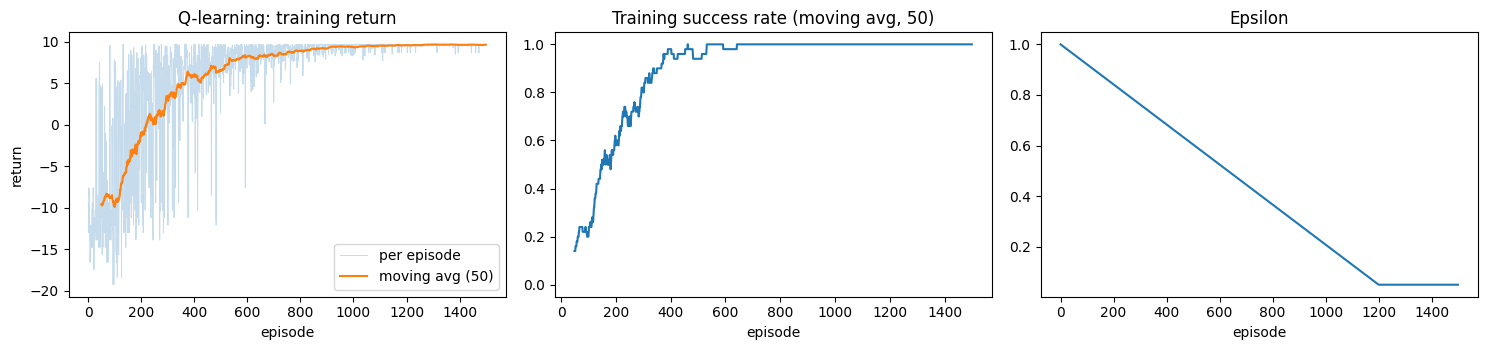

Last 300 episodes (eps = 0.05): success 1.000, mean return 9.65, mean invalid moves 0.03


In [6]:
Q, qlog = train_q()


def moving_avg(x, w: int = 50) -> np.ndarray:
    return np.convolve(np.asarray(x, dtype=float), np.ones(w) / w, mode="valid")


W_AVG = 50
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ep = np.arange(W_AVG - 1, len(qlog["ret"]))
ax[0].plot(qlog["ret"], alpha=0.25, lw=0.7, label="per episode")
ax[0].plot(ep, moving_avg(qlog["ret"], W_AVG), label=f"moving avg ({W_AVG})")
ax[0].set(title="Q-learning: training return", xlabel="episode", ylabel="return")
ax[0].legend()
ax[1].plot(ep, moving_avg(qlog["success"], W_AVG))
ax[1].set(title=f"Training success rate (moving avg, {W_AVG})", xlabel="episode", ylim=(-0.05, 1.05))
ax[2].plot(qlog["eps"])
ax[2].set(title="Epsilon", xlabel="episode")
plt.tight_layout()
plt.show()

last = slice(-300, None)
print(f"Last 300 episodes (eps = 0.05): success {np.mean(qlog['success'][last]):.3f}, "
      f"mean return {np.mean(qlog['ret'][last]):.2f}, "
      f"mean invalid moves {np.mean(qlog['invalid'][last]):.2f}")

In [7]:
q_eval = greedy_rollout(WarehouseEnv(), START, q_policy(Q))
print("Greedy Q-policy from S (eps = 0, no updates):")
print("  positions:", " -> ".join(map(str, q_eval["states"])))
print("  actions  :", [ACTIONS[a] for a in q_eval["actions"]])
print(f"  success={q_eval['success']}  steps={q_eval['steps']}  invalid={q_eval['invalid']}  "
      f"return={q_eval['return']:.1f}  (Task 1 shortest route: 4 steps)")
print()
print(render({"*": q_eval["states"], "S": [START], "G": [GOAL]}))

Greedy Q-policy from S (eps = 0, no updates):
  positions: (2, 0) -> (2, 1) -> (2, 2) -> (2, 3) -> (2, 4)
  actions  : ['Right', 'Right', 'Right', 'Right']
  success=True  steps=4  invalid=0  return=9.7  (Task 1 shortest route: 4 steps)

. . # . .
. . # . .
S * * * G
. . # . .
. . # . .


In [8]:
def random_rollouts(n: int = 100, seed: int = SEED) -> list[dict]:
    rng = np.random.default_rng(seed)
    env = WarehouseEnv()
    return [greedy_rollout(env, START, lambda s: int(rng.integers(5))) for _ in range(n)]


rand = random_rollouts()
succ = [r for r in rand if r["success"]]
print(f"{'Measure':<30}{'Random policy (100 runs)':>26}{'Greedy Q-policy':>18}")
print(f"{'Goal reached':<30}{len(succ) / len(rand):>26.2f}{str(q_eval['success']):>18}")
mean_steps = f"{np.mean([r['steps'] for r in succ]):.1f}" if succ else "n/a"
print(f"{'Steps to goal, if successful':<30}{mean_steps:>26}{q_eval['steps']:>18}")
print(f"{'Timeouts':<30}{np.mean([r['timeout'] for r in rand]):>26.2f}{str(q_eval['timeout']):>18}")
print(f"{'Invalid moves (mean / run)':<30}{np.mean([r['invalid'] for r in rand]):>26.2f}"
      f"{q_eval['invalid']:>18}")

Measure                         Random policy (100 runs)   Greedy Q-policy
Goal reached                                        0.18              True
Steps to goal, if successful                        26.9                 4
Timeouts                                            0.82             False
Invalid moves (mean / run)                          9.86                 0


**(a) Why might the training curve stay noisy after a good route is learned?** Training is still
epsilon-greedy: with $\varepsilon=0.05$, about one action in twenty is random, and a random step
near the doorway (bumping a wall for −1, or stepping back) changes the episode's return. Random
tie-breaking and the table still being updated also move the curve. The curve measures the
*behaviour policy*, not the greedy one.

**(b) Does a high training return imply a good greedy policy?** Not necessarily. The training
return is earned under exploration and under a table that changes during the episode. The greedy
policy can still differ — it may pick a different action in a rarely visited state, or loop if two
values are tied. That is why we evaluate separately with $\varepsilon=0$ and no updates.

**(c) Learning rate $\alpha$ vs exploration probability $\varepsilon$.** $\alpha$ controls *how far*
one estimate moves towards its TD target after an experience (step size of learning).
$\varepsilon$ controls *which experiences are collected*, i.e. how often the agent tries a random
action instead of the current best one. One is about updating, the other about acting.

### Optional investigation — no exploration ($\varepsilon=0$)

In [9]:
print(f"{'run':<28}{'train success (last 300)':>26}{'greedy success':>16}{'greedy steps':>14}")
for seed in (SEED, 11):
    for name, sched in (("eps-greedy", None), ("no exploration", lambda ep: 0.0)):
        Qx, lg = train_q(eps_schedule=sched, seed=seed)
        ev = greedy_rollout(WarehouseEnv(), START, q_policy(Qx))
        print(f"{name + f' (seed {seed})':<28}{np.mean(lg['success'][-300:]):>26.3f}"
              f"{str(ev['success']):>16}{ev['steps']:>14}")

run                           train success (last 300)  greedy success  greedy steps


eps-greedy (seed 7)                              1.000            True             4


no exploration (seed 7)                          1.000            True             4


eps-greedy (seed 11)                             1.000            True             4


no exploration (seed 11)                         1.000            True             4


**Result.** With both seeds, the agent with **no exploration** learned the route as well as the
epsilon-greedy one (4-step greedy path, success 1.000 in the last 300 episodes). This does not mean
exploration is unnecessary. Here the zero-initialised table plus **random tie-breaking** acts as
exploration: every untried action ties at 0 and is picked at random, while tried actions are pushed
*below* 0 by the −0.1/−1 step costs. That is optimism about the unknown, so the agent keeps trying
new actions until it finds the +10. On a larger map, with positive initial values, or with
deterministic tie-breaking, $\varepsilon=0$ can lock onto a poor route.

# Part II — Replace the Table with a Neural Network

## Task 6 — DQN

**What changes:** the $25\times5$ table becomes a network $Q_\theta$ — one-hot(25) → 64 ReLU → 64
ReLU → 5 linear Q-values (no softmax: these are values, not probabilities). Learning now uses
mini-batches from a **replay buffer** (capacity 20,000, batch 64), a **target network**
$Q_{\theta^-}$ copied every 250 optimiser updates, Adam ($10^{-3}$) on the mean squared TD error,
500 warm-up steps, one update every 4 environment steps, 12,000 steps in total, $\varepsilon$ linear
$1\to0.05$ over the first 80 %.

**What stays the same:** the environment, rewards, start, goal, $\gamma=0.95$, the 40-step
truncation, the terminal-vs-truncation rule in the target, epsilon-greedy exploration, and the
separation of training from greedy evaluation.

Target and loss: $y_i=r_i+\gamma(1-d_i)\max_{a'}Q_{\theta^-}(s'_i,a')$ with $d_i=1$ **only** for
true termination, and $L(\theta)=\frac1B\sum_i\big(Q_\theta(s_i,a_i)-y_i\big)^2$.

The recorded action enters the loss in `dqn_loss`: `online(s).gather(1, a)` picks
$Q_\theta(s_i,a_i)$ for the action that was actually taken, so only that output receives an error
signal.

In [10]:
def one_hot(p: Pos) -> np.ndarray:
    v = np.zeros(N * N, dtype=np.float32)
    v[idx(p)] = 1.0
    return v


class QNet(nn.Module):
    def __init__(self, n_in: int, n_out: int, hidden: int = 64):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n_in, hidden), nn.ReLU(),
                                 nn.Linear(hidden, hidden), nn.ReLU(),
                                 nn.Linear(hidden, n_out))       # raw Q-values, no softmax

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


class ReplayBuffer:
    # Fixed-capacity circular store of (s, a, r, s', d); uniform random mini-batches.

    def __init__(self, capacity: int, obs_dim: int, rng: np.random.Generator):
        self.s = np.zeros((capacity, obs_dim), np.float32)
        self.s2 = np.zeros((capacity, obs_dim), np.float32)
        self.a = np.zeros(capacity, np.int64)
        self.r = np.zeros(capacity, np.float32)
        self.d = np.zeros(capacity, np.float32)
        self.capacity, self.ptr, self.size, self.rng = capacity, 0, 0, rng

    def push(self, s, a, r, s2, d) -> None:
        i = self.ptr
        self.s[i], self.a[i], self.r[i], self.s2[i], self.d[i] = s, a, r, s2, d
        self.ptr = (i + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)

    def sample(self, batch: int):
        j = self.rng.integers(0, self.size, batch)
        t = torch.from_numpy
        return t(self.s[j]), t(self.a[j]), t(self.r[j]), t(self.s2[j]), t(self.d[j])


def dqn_loss(online: nn.Module, target: nn.Module, s, a, r, s2, d, gamma: float = GAMMA):
    q_sa = online(s).gather(1, a.unsqueeze(1)).squeeze(1)       # Q_theta(s_i, a_i) for RECORDED a_i
    with torch.no_grad():                                       # targets are constants: no gradient
        y = r + gamma * (1.0 - d) * target(s2).max(dim=1).values
    return ((q_sa - y) ** 2).mean(), q_sa, y


def train_dqn(make_env, encode, obs_dim: int, n_actions: int, total_steps: int,
              seed: int = SEED, buffer_size: int = 20_000, batch: int = 64,
              learning_starts: int = 500, train_every: int = 4, sync_every: int = 250,
              lr: float = 1e-3, eps_frac: float = 0.8):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    online = QNet(obs_dim, n_actions)
    target = copy.deepcopy(online)                  # target initialised from the online network
    for p in target.parameters():
        p.requires_grad_(False)
    opt = torch.optim.Adam(online.parameters(), lr=lr)
    buf = ReplayBuffer(buffer_size, obs_dim, rng)
    env = make_env()
    s, G, n_updates = env.reset(), 0.0, 0
    log = {"ret": [], "success": [], "collision": [], "timeout": [], "end_step": [], "loss": []}
    decay = int(eps_frac * total_steps)

    for t in range(total_steps):
        eps = linear_eps(t, decay)
        with torch.no_grad():
            q = online(torch.from_numpy(encode(s)).unsqueeze(0)).squeeze(0).numpy()
        a = epsilon_greedy(q, eps, rng)
        st = env.step(a)
        # d = 1 only for TRUE termination; truncation stores d = 0 so the target bootstraps.
        buf.push(encode(s), a, st.reward, encode(st.next_state), float(st.terminated))
        G += st.reward
        s = st.next_state                            # next state from BEFORE the reset below
        if st.terminated or st.truncated:
            log["ret"].append(G); log["success"].append(st.success)
            log["collision"].append(st.collision); log["timeout"].append(st.truncated)
            log["end_step"].append(t + 1)
            s, G = env.reset(), 0.0

        if buf.size >= learning_starts and (t + 1) % train_every == 0:
            loss, _, _ = dqn_loss(online, target, *buf.sample(batch))
            opt.zero_grad()
            loss.backward()
            opt.step()
            n_updates += 1
            log["loss"].append(loss.item())
            if n_updates % sync_every == 0:          # periodic target-network synchronisation
                target.load_state_dict(online.state_dict())
    log["n_updates"] = n_updates
    return online, log


def net_policy(net: nn.Module, encode):
    def choose(s) -> int:
        with torch.no_grad():
            return int(net(torch.from_numpy(encode(s)).unsqueeze(0)).argmax(1).item())
    return choose

### Validate the loss before training

Three transitions with hand-computable targets ($\gamma=0.95$): non-terminal $r=1$, next max 2 →
$y=2.9$; terminal $r=5$ → $y=5$ regardless of the next value (we deliberately give it a huge next
value, 100); truncated $r=1$, next max 2, $d=0$ → $y=2.9$. We also check that the loss uses
$Q_\theta(s,a)$ for the **recorded** action and that no gradient reaches the target network.

In [11]:
torch.manual_seed(SEED)
online = QNet(25, 5)


class FixedTarget(nn.Module):
    # Stand-in target net with known outputs, so the targets can be computed by hand.
    def __init__(self, rows: torch.Tensor):
        super().__init__()
        self.w = nn.Parameter(rows.clone())          # a parameter, so we can check it gets no grad

    def forward(self, s2: torch.Tensor) -> torch.Tensor:
        return self.w.expand(s2.shape[0], -1) if self.w.shape[0] == 1 else self.w


s = torch.from_numpy(np.stack([one_hot((2, 1)), one_hot((2, 3)), one_hot((1, 1))]))
s2 = torch.from_numpy(np.stack([one_hot((2, 2)), one_hot((2, 4)), one_hot((1, 0))]))
a = torch.tensor([3, 3, 2])                          # recorded actions: Right, Right, Left
r = torch.tensor([1.0, 5.0, 1.0])
d = torch.tensor([0.0, 1.0, 0.0])                    # only the middle one truly terminates
tgt = FixedTarget(torch.tensor([[2.0, 0.0, -1.0, 1.0, 0.5],      # max 2
                                [100.0, 100.0, 100.0, 100.0, 100.0],  # ignored (terminal)
                                [0.0, 2.0, 1.0, -3.0, 0.0]]))   # max 2

loss, q_sa, y = dqn_loss(online, tgt, s, a, r, s2, d)
print("targets y        :", y.tolist(), " (hand: [2.9, 5.0, 2.9])")
assert torch.allclose(y, torch.tensor([2.9, 5.0, 2.9]))

q_all = online(s).detach()
manual = ((q_all[torch.arange(3), a] - y) ** 2).mean()
wrong = ((q_all[torch.arange(3), (a + 1) % 5] - y) ** 2).mean()
print(f"loss = {loss.item():.6f}  manual MSE on recorded actions = {manual.item():.6f}  "
      f"(MSE on other actions would be {wrong.item():.6f})")
assert torch.isclose(loss, manual)

online.zero_grad()
loss.backward()
grad_online = sum(p.grad.abs().sum().item() for p in online.parameters())
print(f"sum |grad| online = {grad_online:.4f} (> 0);  target grad = {tgt.w.grad} (None expected)")
assert grad_online > 0 and tgt.w.grad is None

# Same check with a real QNet target, as used in training.
real_t = copy.deepcopy(online)
online.zero_grad()
dqn_loss(online, real_t, s, a, r, s2, d)[0].backward()
assert all(p.grad is None for p in real_t.parameters())
print("Real target network after backward(): all grads None -> no gradient flows into the target.")

# Only the recorded action's output gets a gradient: check the last layer's rows.
last = online.net[-1].bias.grad
print("output-bias grad per action:", [round(g, 4) for g in last.tolist()],
      "-> non-zero only for Right (3) and Left (2)")
assert last[[0, 1, 4]].abs().sum() == 0

targets y        : [2.9000000953674316, 5.0, 2.9000000953674316]  (hand: [2.9, 5.0, 2.9])
loss = 13.942918  manual MSE on recorded actions = 13.942918  (MSE on other actions would be 14.590466)
sum |grad| online = 101.6475 (> 0);  target grad = None (None expected)
Real target network after backward(): all grads None -> no gradient flows into the target.
output-bias grad per action: [0.0, 0.0, -0.7666, -4.0282, 0.0] -> non-zero only for Right (3) and Left (2)


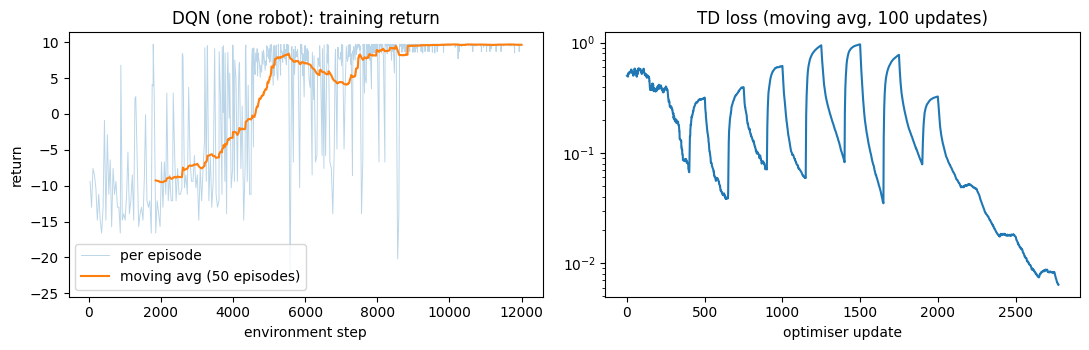

episodes: 1266, optimiser updates: 2876, success in last 50 episodes: 1.00

Greedy DQN from S: (2, 0) -> (2, 1) -> (2, 2) -> (2, 3) -> (2, 4)
success=True  steps=4  invalid=0
Same route as the Q-table policy? True

. . # . .
. . # . .
S * * * G
. . # . .
. . # . .


In [12]:
dqn1, d1log = train_dqn(WarehouseEnv, one_hot, 25, 5, total_steps=12_000)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ret = d1log["ret"]
w = min(W_AVG, max(1, len(ret) // 5))
ax[0].plot(d1log["end_step"], ret, alpha=0.3, lw=0.7, label="per episode")
ax[0].plot(d1log["end_step"][w - 1:], moving_avg(ret, w), label=f"moving avg ({w} episodes)")
ax[0].set(title="DQN (one robot): training return", xlabel="environment step", ylabel="return")
ax[0].legend()
ax[1].plot(moving_avg(d1log["loss"], 100))
ax[1].set(title="TD loss (moving avg, 100 updates)", xlabel="optimiser update", yscale="log")
plt.tight_layout()
plt.show()
print(f"episodes: {len(ret)}, optimiser updates: {d1log['n_updates']}, "
      f"success in last 50 episodes: {np.mean(d1log['success'][-50:]):.2f}")

dqn_eval = greedy_rollout(WarehouseEnv(), START, net_policy(dqn1, one_hot))
print("\nGreedy DQN from S:", " -> ".join(map(str, dqn_eval["states"])))
print(f"success={dqn_eval['success']}  steps={dqn_eval['steps']}  invalid={dqn_eval['invalid']}")
print(f"Same route as the Q-table policy? {dqn_eval['states'] == q_eval['states']}")
print()
print(render({"*": dqn_eval["states"], "S": [START], "G": [GOAL]}))

### Where each DQN component lives

| Component | Location |
|---|---|
| Replay buffer | `ReplayBuffer` (`push` in `train_dqn` after every step) |
| Batch sampling | `ReplayBuffer.sample` — uniform random indices |
| TD target | `dqn_loss`, inside `torch.no_grad()`: `r + gamma * (1 - d) * target(s2).max(1)` |
| Optimiser step | `train_dqn`: `opt.zero_grad(); loss.backward(); opt.step()` every 4 steps after 500 |
| Target synchronisation | `train_dqn`: `target.load_state_dict(online.state_dict())` every 250 updates |

**Comparison.** The one-robot DQN's greedy route is the same 4-step route as the Q-table's,
$(2,0)\to(2,1)\to(2,2)\to(2,3)\to(2,4)$, with no invalid moves. The budgets differ (1,500 episodes
vs 12,000 steps, which is 1,266 episodes here), so this does **not** show which method is more
sample-efficient. On a 21-state problem the table is the natural choice; the network matters when
states are too many to tabulate, as in Part III.

# Part III — Two Robots and Collision Avoidance

## Task 7 — Design the Controller

| Robot | Start | Goal |
|---|---|---|
| A | (2,0) | (2,4) |
| B | (2,4) | (2,0) |

**(a) Why is A's position alone insufficient?** Whether a move is safe — and the team reward —
depends on where B is and where B is moving. Two situations with the same A position but different
B positions need different actions, so A's position is not Markov for the joint task.

**(b) Representation.** The state is the ordered pair $(p_A,p_B)$; the network input is the
concatenation of two length-25 one-hot vectors (50 inputs). Arrival does not need a separate flag:
a robot is "at its goal" exactly when its position equals its goal, and it never leaves.

**(c) Joint actions.** $5\times5=25$, encoded $j=5a_A+a_B$, decoded `a_A, a_B = divmod(j, 5)`.

**(d) One collision-free route.** The doorway is a single cell with walls above and below, so the
robots cannot pass each other in row 2. One plan (A goes first, B steps aside):

| t | A | B |
|---|---|---|
| 0 | (2,0) | (2,4) |
| 1 | (2,1) | (1,4) — B moves up out of the corridor |
| 2 | (2,2) | (1,3) |
| 3 | (2,3) | (1,3) — B waits beside the doorway |
| 4 | (2,4) ✓ | (2,3) — B follows into the cell A just left (allowed) |
| 5 | (2,4) | (2,2) |
| 6 | (2,4) | (2,1) |
| 7 | (2,4) | (2,0) ✓ |

**(e) Where must a robot wait or move aside?** In one of the side cells next to the doorway —
$(1,1)/(3,1)$ on the left or $(1,3)/(3,3)$ on the right — while the other robot passes through
$(2,2)$. Staying in row 2 head-on leads to a same-cell or swap collision.

In [13]:
class TwoRobotEnv:
    # Joint environment: one controller, simultaneous moves, collision and team-reward rules.

    def __init__(self, starts=((2, 0), (2, 4)), goals=((2, 4), (2, 0)), max_steps: int = MAX_STEPS):
        self.starts, self.goals, self.max_steps = tuple(starts), tuple(goals), max_steps
        self.reset()

    def reset(self, starts=None):
        self.pos = tuple(starts) if starts is not None else self.starts
        if not all(map(is_free, self.pos)) or self.pos[0] == self.pos[1]:
            raise ValueError(f"invalid joint start {self.pos}")
        self.t = 0
        return self.pos

    def set_positions(self, pa: Pos, pb: Pos):
        return self.reset((pa, pb))

    def step(self, j: int) -> Step:
        acts = divmod(int(j), 5)                       # (a_A, a_B)
        old = self.pos
        prop, b = [], 0
        for p, a, g in zip(old, acts, self.goals):     # both proposals from the SAME old state
            if p == g:                                 # already home: stays, whatever it requested
                prop.append(p)
                continue
            dr, dc = DELTAS[a]
            cand = (p[0] + dr, p[1] + dc)
            if not is_free(cand):                      # obstacle/boundary -> stay, count invalid
                b += 1
                cand = p
            prop.append(cand)
        self.t += 1
        same_cell = prop[0] == prop[1]
        swap = prop[0] == old[1] and prop[1] == old[0]
        if same_cell or swap:                          # collision overrides every other term
            return Step(old, -10.0, True, False, b, collision=True)   # old positions retained
        self.pos = tuple(prop)
        k = sum(o != g and p == g for o, p, g in zip(old, prop, self.goals))   # NEW arrivals only
        both = all(p == g for p, g in zip(prop, self.goals))
        reward = -0.1 - b + 5 * k + 5 * int(both)
        truncated = (not both) and self.t >= self.max_steps
        return Step(self.pos, reward, both, truncated, b, success=both)


def encode2(state) -> np.ndarray:
    return np.concatenate([one_hot(state[0]), one_hot(state[1])])


def joint(aa: int, ab: int) -> int:
    return 5 * aa + ab

### Test before training — predictions first

| Old A, B | A | B | Prediction |
|---|---|---|---|
| (2,1),(2,3) | Right | Left | Both propose (2,2) → **same-cell collision**, −10, terminate, positions unchanged |
| (2,1),(2,2) | Right | Left | A→(2,2), B→(2,1): they exchange cells → **swap collision**, −10, terminate |
| (2,1),(2,2) | Right | Right | A→(2,2), B→(2,3): A follows into the cell B vacates → **allowed**, −0.1 |
| (2,1),(2,2) | Up | Wait | A→(1,1), B stays → no collision, −0.1 |

Extra tests: a robot at its goal stays put whatever it requests and earns no repeat arrival reward;
a first arrival earns +5; both arriving adds the +5 bonus and terminates; invalid moves cost −1 each
(but not for a robot already home); entering a waiting robot's cell is a collision.

In [14]:
env2 = TwoRobotEnv()
tests2 = [
    # (A, B, aA, aB, expected positions after, reward, terminated, collision, description)
    ((2, 1), (2, 3), R, L, ((2, 1), (2, 3)), -10.0, True, True, "same-cell collision"),
    ((2, 1), (2, 2), R, L, ((2, 1), (2, 2)), -10.0, True, True, "swap collision"),
    ((2, 1), (2, 2), R, R, ((2, 2), (2, 3)), -0.1, False, False, "follow into vacated cell"),
    ((2, 1), (2, 2), U, W, ((1, 1), (2, 2)), -0.1, False, False, "move aside + wait"),
    ((2, 1), (2, 2), R, W, ((2, 1), (2, 2)), -10.0, True, True, "enter a waiting robot's cell"),
    ((2, 4), (0, 0), L, R, ((2, 4), (0, 1)), -0.1, False, False, "A at goal stays, no repeat +5"),
    ((2, 4), (0, 0), U, U, ((2, 4), (0, 0)), -1.1, False, False, "invalid by B only (A home)"),
    ((2, 3), (0, 0), R, W, ((2, 4), (0, 0)), 4.9, False, False, "A's first arrival: -0.1 + 5"),
    ((2, 4), (2, 1), W, L, ((2, 4), (2, 0)), 4.9 + 5, True, False, "B arrives, both home: +5 +5"),
]
print(f"{'description':<32}{'A,B before':<18}{'acts':<14}{'A,B after':<18}{'r':>6}{'term':>6}"
      f"{'coll':>6}  result")
for pa, pb, aa, ab, exp_pos, exp_r, exp_t, exp_c, desc in tests2:
    env2.set_positions(pa, pb)
    st = env2.step(joint(aa, ab))
    ok = (st.next_state == exp_pos and np.isclose(st.reward, exp_r)
          and st.terminated == exp_t and st.collision == exp_c)
    print(f"{desc:<32}{str((pa, pb)):<18}{ACTIONS[aa] + '/' + ACTIONS[ab]:<14}"
          f"{str(st.next_state):<18}{st.reward:>6.1f}{str(st.terminated):>6}{str(st.collision):>6}"
          f"  {'PASS' if ok else 'FAIL'}")
    assert ok

# Repeated arrival: A at home for several steps must never earn +5 again.
env2.set_positions((2, 3), (0, 0))
rs = [env2.step(joint(R, W)).reward] + [env2.step(joint(a, W)).reward for a in (L, R, W)]
print("\nA arrives then requests Left/Right/Wait:", rs, "-> +5 only once")
assert np.isclose(rs[0], 4.9) and all(np.isclose(x, -0.1) for x in rs[1:]) and env2.pos[0] == (2, 4)

# Truncation for the joint task.
env2.reset()
for t in range(1, 41):
    st = env2.step(joint(W, W))
    if st.terminated or st.truncated:
        break
assert t == 40 and st.truncated and not st.terminated
print("40 joint Waits -> truncated at t=40, not terminated. All two-robot tests passed.")

description                     A,B before        acts          A,B after              r  term  coll  result
same-cell collision             ((2, 1), (2, 3))  Right/Left    ((2, 1), (2, 3))   -10.0  True  True  PASS
swap collision                  ((2, 1), (2, 2))  Right/Left    ((2, 1), (2, 2))   -10.0  True  True  PASS
follow into vacated cell        ((2, 1), (2, 2))  Right/Right   ((2, 2), (2, 3))    -0.1 False False  PASS
move aside + wait               ((2, 1), (2, 2))  Up/Wait       ((1, 1), (2, 2))    -0.1 False False  PASS
enter a waiting robot's cell    ((2, 1), (2, 2))  Right/Wait    ((2, 1), (2, 2))   -10.0  True  True  PASS
A at goal stays, no repeat +5   ((2, 4), (0, 0))  Left/Right    ((2, 4), (0, 1))    -0.1 False False  PASS
invalid by B only (A home)      ((2, 4), (0, 0))  Up/Up         ((2, 4), (0, 0))    -1.1 False False  PASS
A's first arrival: -0.1 + 5     ((2, 3), (0, 0))  Right/Wait    ((2, 4), (0, 0))     4.9 False False  PASS
B arrives, both home: +5 +5     ((2

In [15]:
# Independent check of the hand-made route in (d): shortest collision-free joint makespan.
# Reference only — never shown to the learner.
def joint_bfs(starts=((2, 0), (2, 4))) -> int:
    e = TwoRobotEnv()
    frontier, seen = deque([(tuple(starts), 0)]), {tuple(starts)}
    while frontier:
        s, dist = frontier.popleft()
        for j in range(25):
            e.pos, e.t = s, 0
            st = e.step(j)
            if st.collision:
                continue
            if st.success:
                return dist + 1
            if st.next_state not in seen:
                seen.add(st.next_state)
                frontier.append((st.next_state, dist + 1))
    return -1


print("Shortest collision-free joint route (reference):", joint_bfs(), "joint steps")
print("From A=(0,0), B=(4,4) (used in Task 8):", joint_bfs(((0, 0), (4, 4))), "joint steps")

Shortest collision-free joint route (reference): 7 joint steps
From A=(0,0), B=(4,4) (used in Task 8): 9 joint steps


### Train the two-robot DQN

The prompt reused the Task 6 DQN code unchanged except for the input (50) and output (25)
dimensions, plus the joint environment and tests above. No path planner or action filter is used:
the policy is evaluated on the joint actions it chooses. Budget: 60,000 environment steps, seed 7,
Task 6 settings.

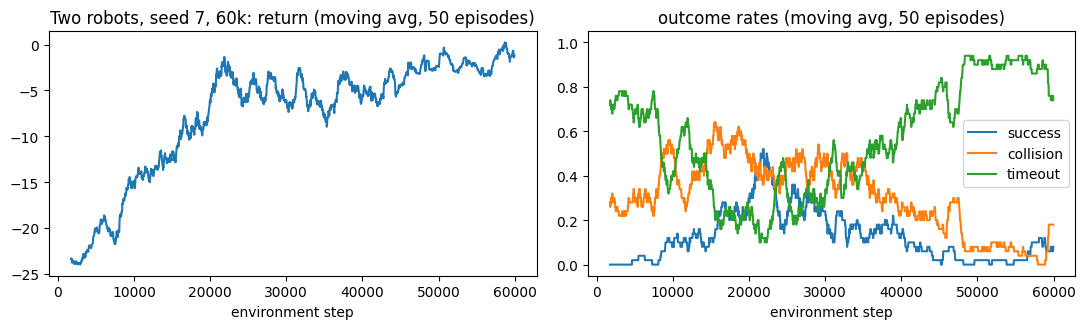

[seed 7, 60k] greedy rollout from A=(2, 0), B=(2, 4):
    t  A       B       joint action    
    0  (2, 0)  (2, 4)  Right/Down      
    1  (2, 1)  (3, 4)  Right/Left      
    2  (2, 2)  (3, 3)  Right/Wait      
    3  (2, 3)  (3, 3)  Right/Wait      
    4  (2, 4)  (3, 3)  Wait/Up         
    5  (2, 4)  (2, 3)  Left/Up         
    6  (2, 4)  (1, 3)  Right/Wait      
    7  (2, 4)  (1, 3)  Right/Wait      
    8  (2, 4)  (1, 3)  Right/Wait      
    9  (2, 4)  (1, 3)  Right/Wait      
   10  (2, 4)  (1, 3)  Right/Wait      
   11  (2, 4)  (1, 3)  Right/Wait      
   12  (2, 4)  (1, 3)  Right/Wait      
   13  (2, 4)  (1, 3)  Right/Wait      
   14  (2, 4)  (1, 3)  Right/Wait      
   15  (2, 4)  (1, 3)  Right/Wait      
   16  (2, 4)  (1, 3)  Right/Wait      
   17  (2, 4)  (1, 3)  Right/Wait      
   18  (2, 4)  (1, 3)  Right/Wait      
   19  (2, 4)  (1, 3)  Right/Wait      
   20  (2, 4)  (1, 3)  Right/Wait      
   21  (2, 4)  (1, 3)  Right/Wait      
   22  (2, 4)  (1, 3)  Rig

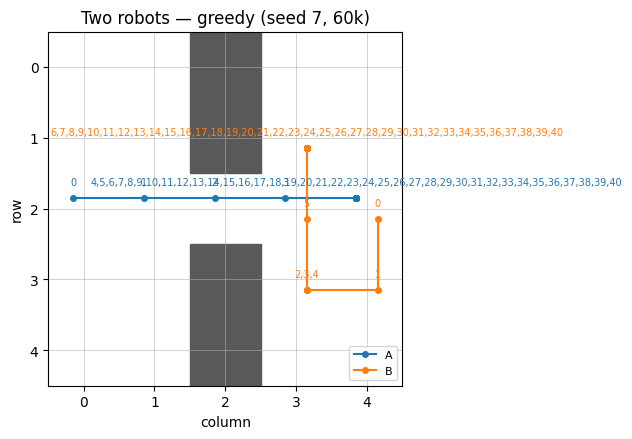

In [16]:
def two_robot_report(net, starts=((2, 0), (2, 4)), title="") -> dict:
    ev = greedy_rollout(TwoRobotEnv(), starts, net_policy(net, encode2))
    print(f"{title}greedy rollout from A={starts[0]}, B={starts[1]}:")
    print(f"  {'t':>3}  {'A':<8}{'B':<8}{'joint action':<16}")
    for t, (s, a) in enumerate(zip(ev["states"], ev["actions"] + [None])):
        act = "" if a is None else "/".join(ACTIONS[x] for x in divmod(a, 5))
        print(f"  {t:>3}  {str(s[0]):<8}{str(s[1]):<8}{act:<16}")
    print(f"  success={ev['success']}  collision={ev['collision']}  timeout={ev['timeout']}  "
          f"steps={ev['steps']}  invalid={ev['invalid']}")
    return ev


def plot_two(ev, title: str) -> None:
    fig, ax = plt.subplots(figsize=(4.6, 4.6))
    for (r_, c_) in OBSTACLES:
        ax.add_patch(plt.Rectangle((c_ - 0.5, r_ - 0.5), 1, 1, color="0.35"))
    for k, (name, col, off) in enumerate((("A", "tab:blue", -0.15), ("B", "tab:orange", 0.15))):
        pts = np.array([s[k] for s in ev["states"]], dtype=float)
        ax.plot(pts[:, 1] + off, pts[:, 0] + off, "-o", color=col, label=name, ms=4)
        last_lbl = {}
        for t, (r_, c_) in enumerate(pts):
            last_lbl.setdefault((r_, c_), []).append(t)
        for (r_, c_), ts in last_lbl.items():   # one label per cell listing all times there
            ax.text(c_ + off, r_ + off - 0.18, ",".join(map(str, ts)), color=col,
                    fontsize=7, ha="center")
    ax.set(xlim=(-0.5, 4.5), ylim=(4.5, -0.5), xticks=range(5), yticks=range(5),
           xlabel="column", ylabel="row", title=title)
    ax.grid(True, lw=0.4)
    ax.set_aspect("equal")
    ax.legend(loc="lower right", fontsize=8)
    plt.show()


def curves_two(log, title: str) -> None:
    w = W_AVG
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
    x = log["end_step"][w - 1:]
    ax[0].plot(x, moving_avg(log["ret"], w))
    ax[0].set(title=f"{title}: return (moving avg, {w} episodes)", xlabel="environment step")
    ax[1].plot(x, moving_avg(log["success"], w), label="success")
    ax[1].plot(x, moving_avg(log["collision"], w), label="collision")
    ax[1].plot(x, moving_avg(log["timeout"], w), label="timeout")
    ax[1].set(title=f"outcome rates (moving avg, {w} episodes)", xlabel="environment step",
              ylim=(-0.05, 1.05))
    ax[1].legend()
    plt.tight_layout()
    plt.show()


dqn2, d2log = train_dqn(TwoRobotEnv, encode2, 50, 25, total_steps=60_000)
curves_two(d2log, "Two robots, seed 7, 60k")
ev2 = two_robot_report(dqn2, title="[seed 7, 60k] ")
plot_two(ev2, "Two robots — greedy (seed 7, 60k)")

### Result of the prescribed run — a failure, kept for inspection

With **seed 7 and 60,000 steps** the greedy policy **does not succeed**. A goes straight through the
doorway and arrives at $t=4$. B correctly moves out of the corridor (to $(3,4)$ and then $(3,3)$)
and lets A pass, but afterwards it returns to $(2,3)$, steps up to $(1,3)$, and **waits there
until the 40-step cutoff**. There is no collision and no invalid move, but the task is not done. The
outcome-rate curves show the same: by the end of training most episodes are timeouts, and success
stays low. This is the case the PDF warns about: a policy can learn to avoid the −10 collision
penalty without learning to deliver. (An extra run with seed 11 at 60k, not shown here, also timed
out: B got through the doorway but then oscillated between $(2,1)$ and $(3,1)$, one step from home.)

All the environment tests above passed, so this is a learning failure, not a rules bug. As the PDF
suggests, we try a **larger budget with the same seed and settings**: 150,000 steps, with ε still
decaying over the first 80 %. Only the budget changes, so the comparison is clean.

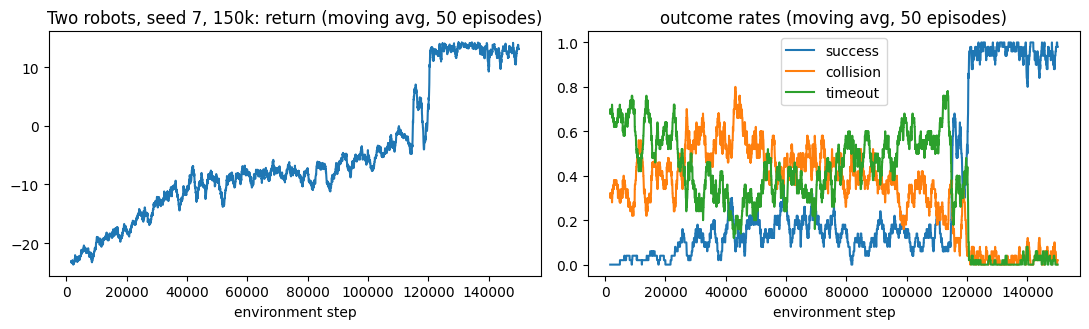

[seed 7, 150k] greedy rollout from A=(2, 0), B=(2, 4):
    t  A       B       joint action    
    0  (2, 0)  (2, 4)  Right/Left      
    1  (2, 1)  (2, 3)  Left/Left       
    2  (2, 0)  (2, 2)  Up/Left         
    3  (1, 0)  (2, 1)  Right/Left      
    4  (1, 1)  (2, 0)  Down/Up         
    5  (2, 1)  (2, 0)  Right/Up        
    6  (2, 2)  (2, 0)  Right/Up        
    7  (2, 3)  (2, 0)  Right/Down      
    8  (2, 4)  (2, 0)                  
  success=True  collision=False  timeout=False  steps=8  invalid=0


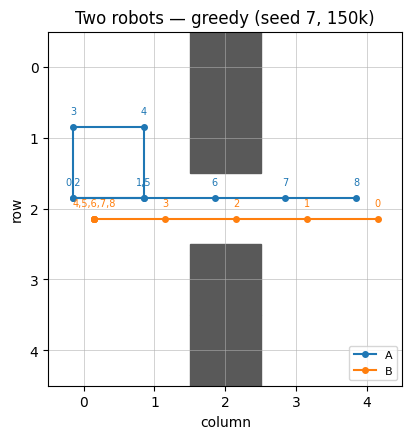

In [17]:
dqn2b, d2blog = train_dqn(TwoRobotEnv, encode2, 50, 25, total_steps=150_000, seed=7)
curves_two(d2blog, "Two robots, seed 7, 150k")
ev2b = two_robot_report(dqn2b, title="[seed 7, 150k] ")
plot_two(ev2b, "Two robots — greedy (seed 7, 150k)")

### Result of run 2 and the Task 7 questions

With **150,000 steps** the greedy joint policy **succeeds in 8 joint steps, with no collision and no
invalid moves**. The shortest collision-free solution, found by the reference BFS, is 7 steps.

Answers refer to the successful run (run 2):

**(a) Which robot entered the passage first?** **B.** It moves left at every step: $(2,3)$ at
$t=1$, the doorway $(2,2)$ at $t=2$, and home at $(2,0)$ at $t=4$. This is the mirror image of our
hand-made plan, in which A went first.

**(b) Where did the other robot yield?** **A**, in the left room. It enters $(2,1)$ at $t=1$, sees
B coming, steps **back** to $(2,0)$ at $t=2$ and then **up into $(1,0)$** at $t=3$, which clears row
2 so that B can come home to $(2,0)$. A then moves to $(1,1)$, follows into $(2,1)$, and goes through
the doorway to arrive at $t=8$. A's first step was wasted, so the route is one step longer than the
optimum. (In the failed run 1 the roles were reversed: B yielded at $(3,3)$ and then $(1,3)$, but
never set off again.)

**(c) Is avoiding collisions sufficient for success?** **No.** Run 1 proves it: zero collisions,
yet a timeout, because B waited forever. Success means **both robots reach their own goals** before
the cutoff; avoiding collisions is necessary but not sufficient.

**(d) Joint-action output size for three robots?** $5^3=125$ outputs (with a $3\times25=75$-input
network). In general $5^n$: the joint action space grows exponentially with the number of robots,
which is one reason a single centralised controller does not scale.

# Task 8 — Evaluate the Agents and the LLM's Contribution

All rollouts below are greedy, with learning disabled.

In [18]:
def row(name, budget, ev):
    outcome = "success" if ev["success"] else ("collision" if ev["collision"] else "timeout")
    steps = ev["steps"] if ev["success"] else "—"
    print(f"{name:<30}{budget:<26}{outcome:<12}{str(steps):<8}{ev['invalid']:<8}")


print(f"{'Controller':<30}{'Budget and seed':<26}{'Outcome':<12}{'Steps':<8}{'Invalid':<8}")
row("Q-table", "1,500 episodes, seed 7", q_eval)
row("DQN, one robot", "12,000 steps, seed 7", dqn_eval)
row("DQN, two robots", "60,000 steps, seed 7", ev2)
row("DQN, two robots (run 2)", "150,000 steps, seed 7", ev2b)

print("\nAdditional starts (no retraining):")
alt_q = greedy_rollout(WarehouseEnv(), (0, 0), q_policy(Q))
alt_d = greedy_rollout(WarehouseEnv(), (0, 0), net_policy(dqn1, one_hot))
row("Q-table from (0,0)", "same table", alt_q)
row("DQN one robot from (0,0)", "same network", alt_d)
print("  Q-table path :", " -> ".join(map(str, alt_q["states"][:12])), "..." if alt_q["steps"] > 11 else "")
print("  DQN path     :", " -> ".join(map(str, alt_d["states"][:12])), "..." if alt_d["steps"] > 11 else "")
print(f"  Q-table rows ever updated: {int((Q != 0).any(1).sum())} of 21 free cells; "
      f"row for (0,0) = {np.round(Q[idx((0, 0))], 2)}")
print("  (shortest route from (0,0) is 6 steps)")

Controller                    Budget and seed           Outcome     Steps   Invalid 
Q-table                       1,500 episodes, seed 7    success     4       0       
DQN, one robot                12,000 steps, seed 7      success     4       0       
DQN, two robots               60,000 steps, seed 7      timeout     —       0       
DQN, two robots (run 2)       150,000 steps, seed 7     success     8       0       

Additional starts (no retraining):
Q-table from (0,0)            same table                success     6       0       
DQN one robot from (0,0)      same network              success     6       0       
  Q-table path : (0, 0) -> (1, 0) -> (2, 0) -> (2, 1) -> (2, 2) -> (2, 3) -> (2, 4) 
  DQN path     : (0, 0) -> (1, 0) -> (1, 1) -> (2, 1) -> (2, 2) -> (2, 3) -> (2, 4) 
  Q-table rows ever updated: 20 of 21 free cells; row for (0,0) = [5.92 7.29 5.92 7.28 6.82]
  (shortest route from (0,0) is 6 steps)


In [19]:
alt2 = two_robot_report(dqn2, starts=((0, 0), (4, 4)), title="[seed 7] ")
alt2b = two_robot_report(dqn2b, starts=((0, 0), (4, 4)), title="[run 2] ")

[seed 7] greedy rollout from A=(0, 0), B=(4, 4):
    t  A       B       joint action    
    0  (0, 0)  (4, 4)  Right/Down      
    1  (0, 1)  (4, 4)  Down/Wait       
    2  (1, 1)  (4, 4)  Down/Up         
    3  (2, 1)  (3, 4)  Right/Left      
    4  (2, 2)  (3, 3)  Right/Wait      
    5  (2, 3)  (3, 3)  Right/Wait      
    6  (2, 4)  (3, 3)  Wait/Up         
    7  (2, 4)  (2, 3)  Left/Up         
    8  (2, 4)  (1, 3)  Right/Wait      
    9  (2, 4)  (1, 3)  Right/Wait      
   10  (2, 4)  (1, 3)  Right/Wait      
   11  (2, 4)  (1, 3)  Right/Wait      
   12  (2, 4)  (1, 3)  Right/Wait      
   13  (2, 4)  (1, 3)  Right/Wait      
   14  (2, 4)  (1, 3)  Right/Wait      
   15  (2, 4)  (1, 3)  Right/Wait      
   16  (2, 4)  (1, 3)  Right/Wait      
   17  (2, 4)  (1, 3)  Right/Wait      
   18  (2, 4)  (1, 3)  Right/Wait      
   19  (2, 4)  (1, 3)  Right/Wait      
   20  (2, 4)  (1, 3)  Right/Wait      
   21  (2, 4)  (1, 3)  Right/Wait      
   22  (2, 4)  (1, 3)  Right/Wa

### Discussion of the comparison and the additional starts

| Measure | Q-table | DQN, one robot | DQN, two robots (run 1) | DQN, two robots (run 2) |
|---|---|---|---|---|
| Budget and seed | 1,500 episodes, seed 7 | 12,000 steps, seed 7 | 60,000 steps, seed 7 | 150,000 steps, seed 7 |
| Success / collision / timeout | success | success | **timeout** | success |
| Steps, if successful | 4 (optimal) | 4 (optimal) | — | 8 (optimum 7) |
| Invalid moves | 0 | 0 | 0 | 0 |
| From the additional start | (0,0): success, 6 (optimal) | (0,0): success, 6 (optimal) | A(0,0), B(4,4): timeout | A(0,0), B(4,4): timeout |

**One robot from (0,0).** Both policies work and take the optimal 6 steps, although they follow
different but equally short routes. This works because $(0,0)$ was visited during training:
epsilon-greedy exploration reached 20 of the 21 free cells, and the $(0,0)$ row of the table holds
sensible values (Down and Right highest). The DQN generalised in the same way.

**Two robots from A=(0,0), B=(4,4).** Both networks **fail** (timeouts). Run 1 reproduces its usual
failure: A arrives, and B again parks at $(1,3)$. Run 2 makes one move and then outputs Wait/Wait
for the rest of the episode. Training always started from $((2,0),(2,4))$, so these joint states
(about 400 valid pairs of distinct free cells) were rarely or never seen. A policy trained from one
fixed start need not work from another, and the joint space makes this much worse than for one
robot. Each greedy rollout is deterministic, so repeating it would not count as more evaluation
trials. Training with random starts would be the fix.

**Raw returns are not compared** across the one- and two-robot tasks, because their reward
definitions differ (team reward with −10/+5/+5 terms vs +10/−1/−0.1).

## Reflection on the LLM's Contribution

1. **What was specified before requesting code?** Everything that defines the problem: the map,
   coordinates, action codes and order, the three mutually exclusive rewards, $\gamma$, the 40-step
   truncation and its *bootstrapping* rule, the Q-table shape and indexing, the epsilon schedule,
   the one-hot encoding, the network shape, all DQN hyper-parameters, the joint state/action
   encoding, the simultaneous-move and collision rules and the team reward. The code was asked only
   to implement that design.
2. **Did the generated code change any rule?** Not in the final version — each rule is pinned by a
   test above. The typical places where generated RL code silently drifts are exactly the ones we
   tested: treating truncation as terminal (`done = terminated or truncated`), using the state
   *after* reset as $s'$, adding an "at goal" reward again on every step a robot waits at home, and
   resolving moves sequentially (A first, then B) instead of simultaneously, which hides swap
   collisions.
3. **Which errors did the tests reveal?** All environment, TD-update and loss tests passed on the final code, so no
rule bug survived into training. The important error was found by the *experiment*: at the
prescribed 60k budget, the two-robot DQN learned to avoid collisions but not to finish. Because every
movement, reward and collision rule had already been tested, we could treat this as a learning
failure rather than an environment bug, and change the budget instead of the rules.
4. **Replay buffer and target network as requested?** Yes: `ReplayBuffer` (capacity 20,000, uniform
   batches of 64) and a separate `target` network initialised by `deepcopy`, frozen
   (`requires_grad=False`), used only under `torch.no_grad()` and synchronised every 250 updates.
   The loss test confirms no gradient reaches it.
5. **Functions I can explain without the LLM:** `WarehouseEnv.step`, `TwoRobotEnv.step`,
   `epsilon_greedy`, `td_target`/`q_update`, `dqn_loss` (especially `gather` on the recorded action
   and the `(1 - d)` factor), and the `train_dqn` loop (warm-up, update frequency, target sync).
6. **What changed, and what is the evidence?** The only change after the first run was the **two-robot training budget,
60k → 150k steps**, with the same seed and hyper-parameters. Evidence: the greedy rollout now
succeeds in 8 joint steps with no collision, and the outcome curves show success replacing timeouts
late in training. As a robustness check outside this notebook, seeds 11 and 3 at 150k also succeeded
(7 steps each). The failed 60k run is kept above, as the PDF requires.

> **Separating claims.** *Asked for:* the specification above. *Implemented:* verified line by line
> by the environment, TD-update and loss tests. *Demonstrated by experiment:* only what the greedy
> rollouts and curves show — for the stated seeds and budgets, not in general.

## Optional — Connecting the Exercise to RLHF

1. **Feedback people provide:** pairwise preferences — shown two recorded trajectories, they pick
   the better one (e.g. the one with no close encounter at the doorway, or with less pointless
   waiting).
2. **What a learned reward model predicts:** a scalar score $\hat r_\phi(\tau)$ (or per step,
   $\hat r_\phi(s,a)$) trained so that preferred trajectories score higher, typically with a
   Bradley–Terry loss $-\log\sigma(\hat r_\phi(\tau^+)-\hat r_\phi(\tau^-))$.
3. **How the agent uses it:** the RL algorithm (Q-learning, DQN, or PPO in LLM fine-tuning)
   optimises the *learned* reward in place of — or in addition to — the hand-written one.

**Does editing the hand-written collision penalty train a reward model?** No. Changing −10 to, say,
−20 is a designer choosing a number; nothing is learned from data and no model generalises to
situations the designer did not anticipate. Learning from preferences fits a reward *function* to
human judgements, so it can capture qualities that are easy to recognise but hard to write down
(“that pass was too close”). This lab only uses the hand-written reward.

## Summary and Reproducibility

* **MDP:** state = position (or the ordered pair of positions for two robots); 5 actions (25
  joint actions); deterministic moves; mutually exclusive rewards; goal = termination, 40 steps =
  truncation (which still bootstraps).
* **Q-learning** (1,500 episodes) learned the optimal 4-step route, and also works from $(0,0)$ (6
  steps, optimal). The random policy reached the goal in 18 % of 100 runs, in 26.9 steps on average.
* **DQN, one robot** (12,000 steps) learned the same optimal route; the loss was validated against
  hand-computed targets, and no gradient reached the target network.
* **DQN, two robots:** all simultaneous-move, collision and reward tests pass. With the prescribed 60k
  steps the policy avoided collisions but timed out (B waited forever). With 150k steps it succeeded
  in 8 joint steps (optimum 7): B went through first, and A yielded at $(1,0)$. Neither network
  generalises to the unseen start A=(0,0), B=(4,4).

**Reproduce:** run all cells top to bottom (CPU, a few minutes). Versions are printed in the first
code cell. Seed 7 for every run (the optional no-exploration check also uses 11). Budgets: Q-learning
1,500 episodes; one-robot DQN 12,000 steps; two-robot DQN 60,000 steps (run 2: 150k).